# 05 — Analyse du re-ranker Mistral-7B (QLoRA)

Ablation sur le **rang LoRA** ($r \in \{4, 8, 16\}$) et analyse des **courbes d'entraînement**.

Pipeline : BM25 top-20 → Mistral-7B-Instruct + adaptateur LoRA → top-10 final.

Score de pertinence : $s(q, p) = \text{logit}(\texttt{yes}) - \text{logit}(\texttt{no})$ sur le dernier token généré.

## 1. Setup & chargement des métriques

In [1]:
import json
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np

RESULTS = Path('../results')
OUT_DIR = RESULTS / 'analysis' / '05_mistral_reranker'
OUT_DIR.mkdir(parents=True, exist_ok=True)

COLORS = {
    'rouge':      '#C8102E',
    'or':         '#F0A500',
    'bleu_nuit':  '#1A2D5A',
    'gris_fonce': '#4A4A4A',
    'gris_clair': '#D3D3D3',
}

def load(path):
    return json.loads(Path(path).read_text())

bm25   = load(RESULTS / 'baselines/bm25_msmarco_dev/metrics.json')
m_zs   = load(RESULTS / 'mistral/evaluation/mistral_zero_shot_msmarco_dev/metrics.json')
m_r4   = load(RESULTS / 'mistral/evaluation/mistral_r4_msmarco_dev/metrics.json')
m_r8   = load(RESULTS / 'mistral/evaluation/mistral_r8_msmarco_dev/metrics.json')
m_r16  = load(RESULTS / 'mistral/evaluation/mistral_r16_msmarco_dev/metrics.json')

tl_r4  = load(RESULTS / 'mistral/training/mistral_lora_r4/training_loss.json')
tl_r8  = load(RESULTS / 'mistral/training/mistral_lora_r8/training_loss.json')
tl_r16 = load(RESULTS / 'mistral/training/mistral_lora_r16/training_loss.json')

print('BM25    MRR@10 =', bm25['MRR@10'])
print('Mistral ZS     =', m_zs['MRR@10'])
print('Mistral r=4    =', m_r4['MRR@10'])
print('Mistral r=8    =', m_r8['MRR@10'], '← meilleur')
print('Mistral r=16   =', m_r16['MRR@10'])

BM25    MRR@10 = 0.1697
Mistral ZS     = 0.20434944512666575
Mistral r=4    = 0.26762619047619046
Mistral r=8    = 0.27475326329194527 ← meilleur
Mistral r=16   = 0.26970714285714287


## 2. Figure 1 — Ablation sur le rang LoRA (MRR@10)

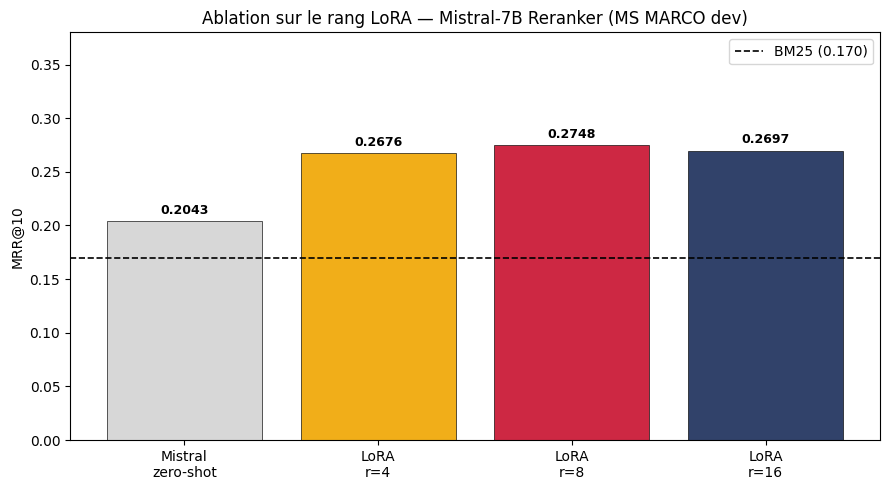

Figure sauvegardée : ../results/analysis/05_mistral_reranker/lora_rank_ablation.png


In [2]:
labels  = ['Mistral\nzero-shot', 'LoRA\nr=4', 'LoRA\nr=8', 'LoRA\nr=16']
mrr_vals = [m_zs['MRR@10'], m_r4['MRR@10'], m_r8['MRR@10'], m_r16['MRR@10']]
bar_colors = [COLORS['gris_clair'], COLORS['or'], COLORS['rouge'], COLORS['bleu_nuit']]

fig, ax = plt.subplots(figsize=(9, 5))
bars = ax.bar(labels, mrr_vals, color=bar_colors, edgecolor='black', linewidth=0.5, alpha=0.9)
ax.axhline(bm25['MRR@10'], color='black', linestyle='--', linewidth=1.2,
           label=f"BM25 ({bm25['MRR@10']:.3f})")

for bar, val in zip(bars, mrr_vals):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.004,
            f'{val:.4f}', ha='center', va='bottom', fontsize=9, fontweight='bold')

ax.set_ylabel('MRR@10')
ax.set_ylim(0, 0.38)
ax.set_title('Ablation sur le rang LoRA — Mistral-7B Reranker (MS MARCO dev)')
ax.legend()
plt.tight_layout()
plt.savefig(OUT_DIR / 'lora_rank_ablation.png', dpi=150)
plt.show()
print(f'Figure sauvegardée : {OUT_DIR / "lora_rank_ablation.png"}')

## 3. Figure 2 — Courbes de perte d'entraînement (r=4, 8, 16)

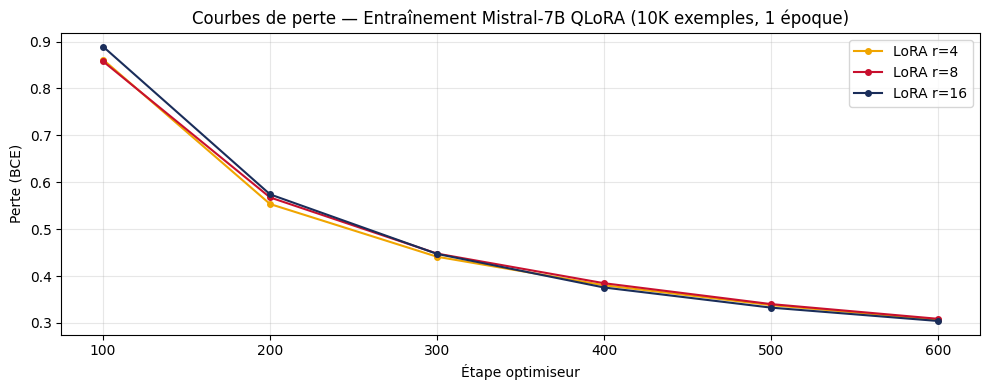

Figure sauvegardée : ../results/analysis/05_mistral_reranker/training_loss_curves.png


In [3]:
fig, ax = plt.subplots(figsize=(10, 4))

for tl, label, color in [
    (tl_r4,  'r=4',  COLORS['or']),
    (tl_r8,  'r=8',  COLORS['rouge']),
    (tl_r16, 'r=16', COLORS['bleu_nuit']),
]:
    steps  = [d['step'] for d in tl]
    losses = [d['loss'] for d in tl]
    ax.plot(steps, losses, marker='o', markersize=4, label=f'LoRA {label}', color=color)

ax.set_xlabel('Étape optimiseur')
ax.set_ylabel('Perte (BCE)')
ax.set_title('Courbes de perte — Entraînement Mistral-7B QLoRA (10K exemples, 1 époque)')
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(OUT_DIR / 'training_loss_curves.png', dpi=150)
plt.show()
print(f'Figure sauvegardée : {OUT_DIR / "training_loss_curves.png"}')

## 4. Figure 3 — Comparaison multi-métriques (MRR, nDCG, Recall@10)

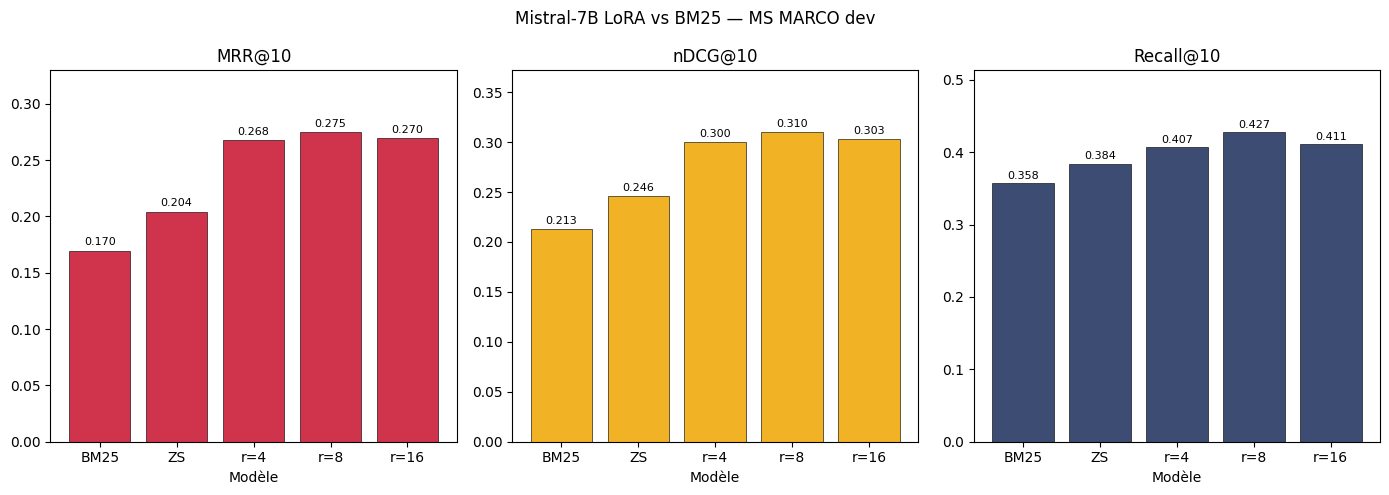

Figure sauvegardée : ../results/analysis/05_mistral_reranker/mistral_multi_metric.png


In [4]:
systems = ['BM25', 'ZS', 'r=4', 'r=8', 'r=16']
all_metrics = [
    [bm25['MRR@10'],  bm25['nDCG@10'],  bm25['Recall@10']],
    [m_zs['MRR@10'], m_zs['nDCG@10'], m_zs['Recall@10']],
    [m_r4['MRR@10'], m_r4['nDCG@10'], m_r4['Recall@10']],
    [m_r8['MRR@10'], m_r8['nDCG@10'], m_r8['Recall@10']],
    [m_r16['MRR@10'],m_r16['nDCG@10'],m_r16['Recall@10']],
]
metric_names = ['MRR@10', 'nDCG@10', 'Recall@10']
metric_colors = [COLORS['rouge'], COLORS['or'], COLORS['bleu_nuit']]

fig, axes = plt.subplots(1, 3, figsize=(14, 5), sharey=False)
for ax, metric_name, col_idx, color in zip(axes, metric_names, range(3), metric_colors):
    vals = [m[col_idx] for m in all_metrics]
    bars = ax.bar(systems, vals, color=color, alpha=0.85, edgecolor='black', linewidth=0.5)
    for bar, val in zip(bars, vals):
        ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.003,
                f'{val:.3f}', ha='center', va='bottom', fontsize=8)
    ax.set_title(metric_name)
    ax.set_ylim(0, max(vals) * 1.2)
    ax.set_xlabel('Modèle')

fig.suptitle('Mistral-7B LoRA vs BM25 — MS MARCO dev', fontsize=12)
plt.tight_layout()
plt.savefig(OUT_DIR / 'mistral_multi_metric.png', dpi=150)
plt.show()
print(f'Figure sauvegardée : {OUT_DIR / "mistral_multi_metric.png"}')